# Energy, priorities and fairness

Occupancy flow turns discounted resource-constrained control into a linear program. Budgets use normalized discounted costs. A service-floor extension is an explicit new requirement, rather than an undocumented change to the original reward.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/decision_lab').is_dir()
sys.path.insert(0, str(ROOT / 'src'))
def read(path): return json.loads((ROOT / path).read_text())


## A randomized constrained optimum

In [2]:
from decision_lab.mdp import FiniteMDP, discounted_occupancy
mdp = FiniteMDP(np.ones((1,2,1)), np.array([[0.,1.]]))
result = discounted_occupancy(mdp,.9,costs=np.array([[[0.,1.]]]),budgets=[.25])
assert np.allclose(result["policy"], [[.75,.25]],atol=1e-8)
print("policy",result["policy"],"cost",result["normalized_costs"],"shadow",result["budget_shadow_prices"])

policy [[0.75 0.25]] cost [0.25] shadow [10.]


## Declared physical tradeoffs

In [3]:
pareto = pd.DataFrame(read("results/reference/planning/metrics.json")["pareto"])
assert pareto.flow_residual.max()<1e-8
pareto.head(8)

,profile,priorities,fairness_constraint,energy_budget,normalized_weighted_loss,normalized_energy,user_service,flow_residual,budget_shadow_prices,primal_dual_gap
0,per_user,"[1.0, 1.0]",False,0.15,1.543,0.15,"[0.0006103232169713093, 0.14938967678302875]",6.379619e-14,[99.99999999993736],1.111289e-11
1,per_user,"[1.0, 1.0]",True,0.15,1.543,0.15,"[0.1460535657470704, 0.003946434252929568]",3.462508e-14,"[99.99999999996461, 0.0]",1.847411e-12
2,per_user,"[1.0, 1.0]",False,0.25,1.443,0.25,"[0.07952872571032911, 0.17047127428967088]",1.203065e-13,[100.00000000014643],1.108447e-11
3,per_user,"[1.0, 1.0]",True,0.25,1.443,0.25,"[0.23457524064435858, 0.015424759355641257]",2.305309e-13,"[99.99999999988279, 0.0]",2.472689e-12
4,per_user,"[1.0, 1.0]",False,0.35,1.343,0.35,"[0.15570444642484677, 0.1942955535751529]",6.661685e-14,[99.99999999992906],8.498091e-12
5,per_user,"[1.0, 1.0]",True,0.35,1.343,0.35,"[0.23924547725375356, 0.11075452274624648]",1.687539e-14,"[100.00000000005826, 0.0]",8.242296e-13
6,per_user,"[1.0, 1.0]",False,0.45,1.243,0.45,"[0.2271641080473573, 0.2228358919526427]",6.038919e-14,[100.00000000001445],1.332978e-11
7,per_user,"[1.0, 1.0]",True,0.45,1.243,0.45,"[0.24003074700718421, 0.2099692529928154]",5.938999e-14,"[99.99999999998977, 0.0]",7.162271e-12


## Priorities change the objective

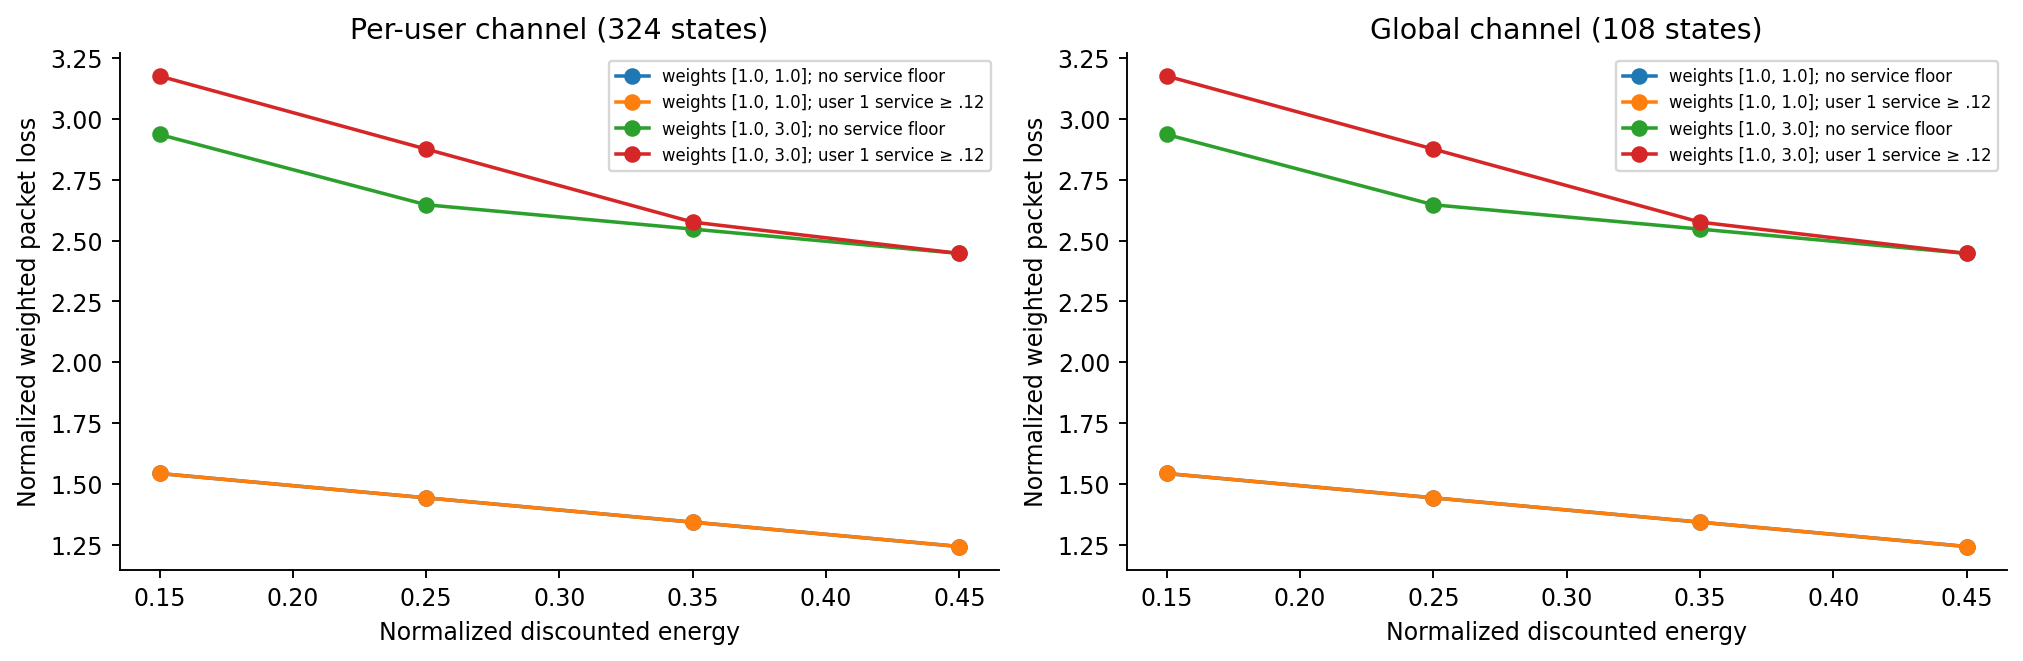

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "assets/figures/constrained_planning.png")))

Full fits: `decision-lab planning --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.